# 04. Backtesting and Model Comparison

**Goal:** decide fairly which forecasting method to use for the next 30 days.

Every method is tested on the **same 35 rolling origins** used in notebook 02. At each origin a method sees only earlier days, forecasts the next 30, and is scored on what really happened. Models are **refitted at every origin**, and their settings (orders) are fixed in advance, so no method sees the future.

**Methods**
- Baselines from notebook 02: naive_last, seasonal_naive, weekday_avg_4w, mean_7d, mean_28d
- Holt-Winters: no trend and damped trend (weekly seasonality)
- ARIMA(0,1,1), ARIMA(1,1,1) and SARIMA(0,1,1)(1,0,1,7)
- `combo`: the plain average of mean_7d, weekday_avg_4w and Holt-Winters (no trend). Averaging several forecasts often helps.

**Scores:** MAE and WAPE are the main ones. SMAPE is shown but is inflated by very low-sales days.

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")   # statsmodels convergence notices; results are checked below

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
BROWN, RED, GREEN, GREY, BLUE = "#6F4E37", "#C1272D", "#2A7F62", "#8A8A8A", "#3B6EA5"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()

def metrics(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = ~np.isnan(a) & ~np.isnan(f)
    a, f = a[ok], f[ok]
    return {"MAE": np.mean(np.abs(a - f)), "RMSE": np.sqrt(np.mean((a - f) ** 2)),
            "WAPE": np.sum(np.abs(a - f)) / np.sum(a),
            "SMAPE": np.mean(2 * np.abs(a - f) / (np.abs(a) + np.abs(f))),
            "Bias": np.mean(f - a), "n_days": int(ok.sum())}

daily = pd.read_csv(ROOT / "data" / "processed" / "daily_sales.csv", parse_dates=["date"], index_col="date")
y = daily["revenue"].where(daily["reported"])      # NaN where there is no data
H, START = 30, 120
origins = list(range(START, len(y) - H + 1, 7))
print(f"{len(origins)} rolling origins: {y.index[origins[0]].date()} to {y.index[origins[-1]].date()}")

35 rolling origins: 2024-06-29 to 2025-02-22


## 1. The forecasters

In [2]:
# ---- baselines (same definitions as notebook 02) ----
def _same_weekday_values(hist, target_date, weeks):
    last = hist.index[-1]
    vals = []
    for k in range(1, weeks + 1):
        back = (last.weekday() - target_date.weekday()) % 7
        d = last - pd.Timedelta(days=back + 7 * (k - 1))
        if d in hist.index:
            vals.append(hist.loc[d])
    return np.array(vals, float)

def naive_last(hist, dates):
    return np.full(len(dates), hist.dropna().iloc[-1])

def seasonal_naive(hist, dates):
    out = []
    for t in dates:
        v = _same_weekday_values(hist, t, 6); v = v[~np.isnan(v)]
        out.append(v[0] if len(v) else hist.mean())
    return np.array(out)

def weekday_avg_4w(hist, dates):
    out = []
    for t in dates:
        v = _same_weekday_values(hist, t, 4)
        out.append(np.nanmean(v) if np.any(~np.isnan(v)) else hist.mean())
    return np.array(out)

def mean_7d(hist, dates):  return np.full(len(dates), hist.iloc[-7:].mean())
def mean_28d(hist, dates): return np.full(len(dates), hist.iloc[-28:].mean())

# ---- statistical models: refitted on the history of each origin ----
def _fill(hist):
    return hist.interpolate(limit_direction="both").asfreq("D")   # gaps filled using days before the origin only

def hw_no_trend(hist, dates):
    h = _fill(hist)
    return ExponentialSmoothing(h, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit().forecast(len(dates)).values

def hw_damped(hist, dates):
    h = _fill(hist)
    return ExponentialSmoothing(h, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7,
                                initialization_method="estimated").fit().forecast(len(dates)).values

def arima_011(hist, dates):
    return ARIMA(_fill(hist), order=(0, 1, 1)).fit().forecast(len(dates)).values

def arima_111(hist, dates):
    return ARIMA(_fill(hist), order=(1, 1, 1)).fit().forecast(len(dates)).values

def sarima_011_101(hist, dates):
    return SARIMAX(_fill(hist), order=(0, 1, 1), seasonal_order=(1, 0, 1, 7)).fit(disp=False, maxiter=100).forecast(len(dates)).values

MODELS = {
    "naive_last": naive_last, "seasonal_naive": seasonal_naive, "weekday_avg_4w": weekday_avg_4w,
    "mean_7d": mean_7d, "mean_28d": mean_28d,
    "HW_no_trend": hw_no_trend, "HW_damped": hw_damped,
    "ARIMA_011": arima_011, "ARIMA_111": arima_111, "SARIMA_011_101_7": sarima_011_101,
}
FAMILY = {m: "baseline" for m in ["naive_last", "seasonal_naive", "weekday_avg_4w", "mean_7d", "mean_28d"]}
FAMILY.update({m: "Holt-Winters" for m in ["HW_no_trend", "HW_damped"]})
FAMILY.update({m: "ARIMA" for m in ["ARIMA_011", "ARIMA_111", "SARIMA_011_101_7"]})
FAMILY["combo"] = "average"

## 2. Run the backtest

At each origin, every model is refitted on the days before it and forecasts the next 30 days.

In [3]:
t0 = time.time()
records = []
for o in origins:
    hist, dates = y.iloc[:o], y.index[o:o + H]
    actual = y.iloc[o:o + H].values
    fc = {}
    for name, fn in MODELS.items():
        try:
            fc[name] = np.asarray(fn(hist, dates), float)
        except Exception as e:
            fc[name] = np.full(H, np.nan)
    fc["combo"] = np.mean([fc["mean_7d"], fc["weekday_avg_4w"], fc["HW_no_trend"]], axis=0)
    for name, f_ in fc.items():
        for h in range(H):
            records.append((name, o, h + 1, dates[h], f_[h], actual[h]))
bt = pd.DataFrame(records, columns=["model", "origin", "h", "date", "forecast", "actual"])
print(f"{bt['model'].nunique()} models x {len(origins)} origins done in {time.time() - t0:.0f} s; failed fits: {int(bt['forecast'].isna().sum())} forecast days")
bt.to_csv(TAB / "backtest_forecasts_all.csv", index=False)

11 models x 35 origins done in 53 s; failed fits: 0 forecast days


In [4]:
# Cross-check against notebook 02 on the same origins (baselines must give identical numbers)
chk = {m: metrics(g["actual"], g["forecast"])["MAE"] for m, g in bt.groupby("model")}
print({k: round(chk[k], 1) for k in ["mean_7d", "weekday_avg_4w", "seasonal_naive"]}, "-> notebook 02: mean_7d 139.8, weekday_avg_4w 142.0, seasonal_naive 163.8")

{'mean_7d': np.float64(139.8), 'weekday_avg_4w': np.float64(142.0), 'seasonal_naive': np.float64(163.8)} -> notebook 02: mean_7d 139.8, weekday_avg_4w 142.0, seasonal_naive 163.8


## 3. Results over all 35 origins

In [5]:
def summarise(frame):
    return pd.DataFrame({m: metrics(g["actual"], g["forecast"]) for m, g in frame.groupby("model")}).T

allo = summarise(bt)
allo.insert(0, "family", allo.index.map(FAMILY))
allo = allo.sort_values("MAE")
allo["MAE vs seasonal_naive"] = allo["MAE"] / allo.loc["seasonal_naive", "MAE"] - 1
display(allo.round(3))

,family,MAE,RMSE,WAPE,SMAPE,Bias,n_days,MAE vs seasonal_naive
combo,average,135.735,172.865,0.423,0.462,-20.293,1033.0,-0.171
HW_no_trend,Holt-Winters,136.631,175.059,0.425,0.462,-16.508,1033.0,-0.166
SARIMA_011_101_7,ARIMA,137.441,175.718,0.428,0.463,-17.412,1033.0,-0.161
ARIMA_011,ARIMA,137.451,175.854,0.428,0.464,-16.224,1033.0,-0.161
ARIMA_111,ARIMA,137.569,176.216,0.428,0.465,-16.432,1033.0,-0.160
HW_damped,Holt-Winters,138.242,177.216,0.430,0.469,-17.629,1033.0,-0.156
mean_7d,baseline,139.768,178.700,0.435,0.477,-17.140,1033.0,-0.147
mean_28d,baseline,140.976,178.145,0.439,0.471,-25.537,1033.0,-0.139
weekday_avg_4w,baseline,141.965,180.748,0.442,0.480,-27.232,1033.0,-0.133
naive_last,baseline,157.209,202.936,0.490,0.520,-11.804,1033.0,-0.040


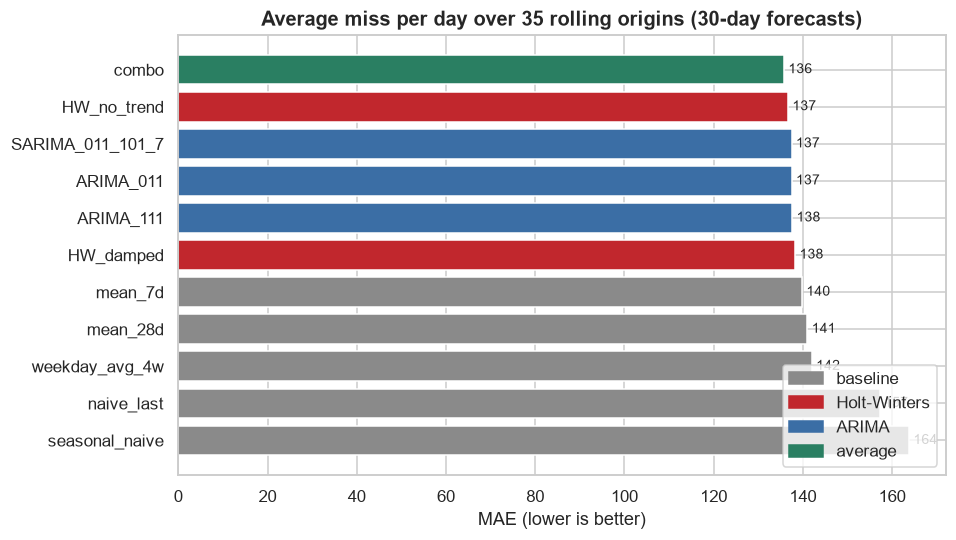

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.2))
col = {"baseline": GREY, "Holt-Winters": RED, "ARIMA": BLUE, "average": GREEN}
ax.barh(allo.index, allo["MAE"], color=[col[f] for f in allo["family"]])
ax.invert_yaxis()
for i, (m, r) in enumerate(allo.iterrows()):
    ax.text(r["MAE"] + 1, i, f"{r['MAE']:.0f}", va="center", fontsize=9)
ax.set(title="Average miss per day over 35 rolling origins (30-day forecasts)", xlabel="MAE (lower is better)", ylabel="")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in col.values()]
ax.legend(handles, col.keys(), loc="lower right")
save_fig("15_final_mae.png")

## 4. Is the ranking reliable?

The 35 windows overlap, so they are not 35 independent tests. Still, we can ask in how many windows each model beats a reference, and how large the typical gap is.

In [7]:
per_origin = (bt.assign(abs_err=lambda t: (t["actual"] - t["forecast"]).abs())
                .groupby(["model", "origin"])["abs_err"].mean().unstack(0))
per_origin.index = [y.index[o] for o in per_origin.index]
per_origin.round(2).to_csv(TAB / "per_origin_mae.csv")

def versus(ref):
    rows = {}
    for m in per_origin.columns:
        d = per_origin[m] - per_origin[ref]
        rows[m] = {"wins vs " + ref: (d < 0).mean(), "median MAE gap": d.median(), "mean MAE gap": d.mean()}
    return pd.DataFrame(rows).T.sort_values("mean MAE gap")

display(versus("seasonal_naive").drop("seasonal_naive").round(3))
display(versus("mean_7d").drop("mean_7d").round(3))

,wins vs seasonal_naive,median MAE gap,mean MAE gap
combo,0.829,-36.453,-28.162
HW_no_trend,0.829,-35.158,-27.318
SARIMA_011_101_7,0.829,-34.568,-26.526
ARIMA_011,0.829,-33.914,-26.517
ARIMA_111,0.857,-33.654,-26.402
HW_damped,0.857,-31.550,-25.732
mean_7d,0.857,-30.497,-24.181
mean_28d,0.771,-24.281,-22.981
weekday_avg_4w,0.771,-21.744,-21.888
naive_last,0.714,-17.403,-7.006


,wins vs mean_7d,median MAE gap,mean MAE gap
combo,0.571,-1.863,-3.981
HW_no_trend,0.543,-1.528,-3.138
SARIMA_011_101_7,0.429,0.297,-2.345
ARIMA_011,0.486,0.114,-2.336
ARIMA_111,0.514,-0.123,-2.221
HW_damped,0.486,0.062,-1.552
mean_28d,0.514,-0.413,1.200
weekday_avg_4w,0.429,3.155,2.292
naive_last,0.314,2.000,17.174
seasonal_naive,0.143,30.497,24.181


,origins before Nov 2024,origins from Nov 2024,rank early,rank late
model,,,,
combo,143.3,126.9,2,1
HW_damped,146.5,128.5,8,2
HW_no_trend,143.4,128.5,3,2
ARIMA_111,144.8,128.9,6,4
ARIMA_011,144.4,129.1,5,5
SARIMA_011_101_7,144.0,129.5,4,6
mean_7d,146.2,132.1,7,7
weekday_avg_4w,149.5,133.2,9,8
naive_last,177.0,134.8,10,9


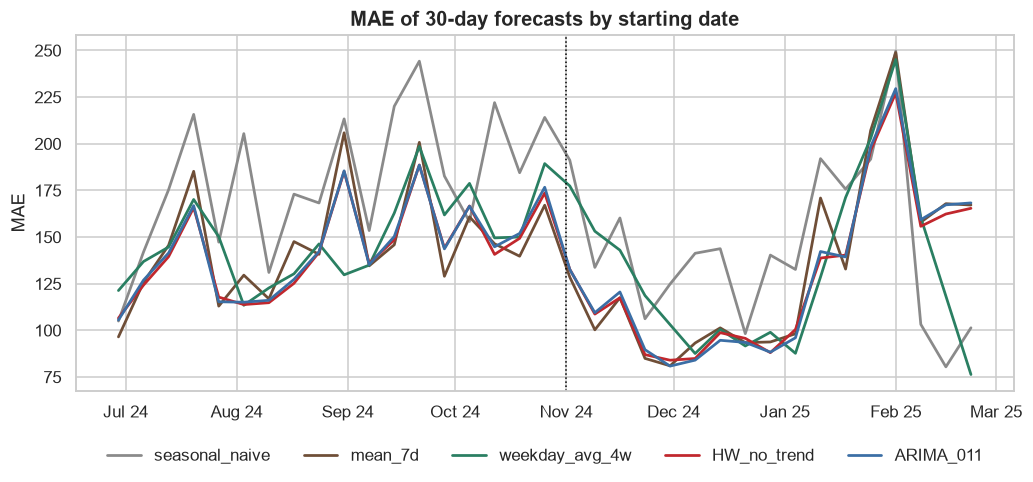

In [8]:
# Same ranking, split into earlier and later origins: does the winner stay the same?
split = pd.Timestamp("2024-11-01")
early = per_origin[per_origin.index < split].mean()
late = per_origin[per_origin.index >= split].mean()
half = pd.DataFrame({"origins before Nov 2024": early, "origins from Nov 2024": late}).round(1)
half["rank early"] = half.iloc[:, 0].rank().astype(int)
half["rank late"] = half.iloc[:, 1].rank().astype(int)
display(half.sort_values("origins from Nov 2024"))

fig, ax = plt.subplots(figsize=(11, 4.2))
for m, c in [("seasonal_naive", GREY), ("mean_7d", BROWN), ("weekday_avg_4w", GREEN), ("HW_no_trend", RED), ("ARIMA_011", BLUE)]:
    ax.plot(per_origin.index, per_origin[m], lw=1.8, label=m, color=c)
ax.axvline(split, color="black", ls=":", lw=1)
ax.set(title="MAE of 30-day forecasts by starting date", ylabel="MAE"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.12), frameon=False)
save_fig("16_mae_by_origin.png")

## 5. Error by forecast horizon

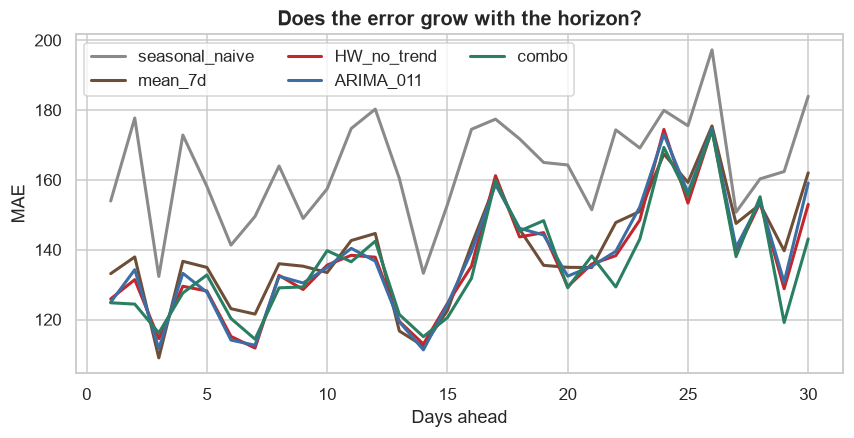

MAE, day 1-7 vs day 24-30:


model,ARIMA_011,ARIMA_111,HW_damped,HW_no_trend,SARIMA_011_101_7,combo,mean_28d,mean_7d,naive_last,seasonal_naive,weekday_avg_4w
days 1-7,122.7,122.6,123.3,122.4,123.3,122.9,128.7,128.0,144.2,155.1,130.6
days 24-30,155.5,156.3,156.9,153.8,154.2,150.6,152.0,157.8,175.8,172.9,152.4


In [9]:
by_h = (bt.assign(abs_err=lambda t: (t["actual"] - t["forecast"]).abs())
          .groupby(["model", "h"])["abs_err"].mean().unstack(0))
fig, ax = plt.subplots(figsize=(9, 4))
for m, c in [("seasonal_naive", GREY), ("mean_7d", BROWN), ("HW_no_trend", RED), ("ARIMA_011", BLUE), ("combo", GREEN)]:
    ax.plot(by_h.index, by_h[m], lw=2, label=m, color=c)
ax.set(title="Does the error grow with the horizon?", xlabel="Days ahead", ylabel="MAE"); ax.legend(ncol=3)
save_fig("17_error_by_horizon.png")
print("MAE, day 1-7 vs day 24-30:")
display(pd.DataFrame({"days 1-7": by_h.loc[1:7].mean(), "days 24-30": by_h.loc[24:30].mean()}).round(1).T)

## 6. Does the 95% interval hold up?

In [10]:
cover = []
for o in origins:
    hist = _fill(y.iloc[:o]); dates = y.index[o:o + H]; actual = y.iloc[o:o + H].values
    fc = ARIMA(hist, order=(0, 1, 1)).fit().get_forecast(H)
    ci = fc.conf_int(alpha=.05).values
    ok = ~np.isnan(actual)
    cover.append(((actual >= ci[:, 0]) & (actual <= ci[:, 1]))[ok])
cov = np.concatenate(cover)
print(f"ARIMA(0,1,1) 95% interval covered {cov.mean():.0%} of {len(cov)} test days over all origins (target about 95%)")

ARIMA(0,1,1) 95% interval covered 91% of 1033 test days over all origins (target about 95%)


## 7. Last 30 days: best methods against what happened

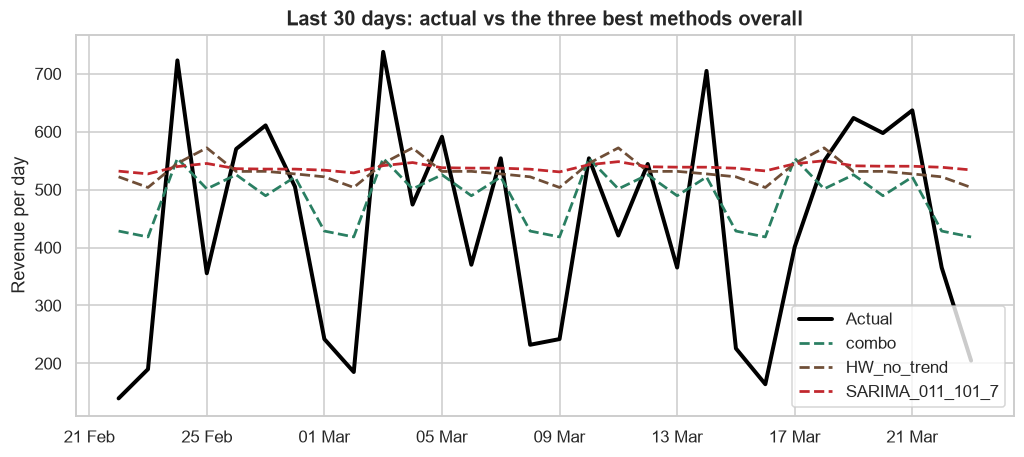

,MAE,RMSE,WAPE,SMAPE,Bias,n_days
weekday_avg_4w,76.339,98.097,0.175,0.181,-33.118,30.0
seasonal_naive,101.383,118.743,0.233,0.257,74.471,30.0
combo,129.860,151.236,0.298,0.336,50.695,30.0
mean_28d,162.778,183.806,0.373,0.404,-20.902,30.0
HW_damped,165.080,198.145,0.379,0.400,94.577,30.0
HW_no_trend,165.399,198.843,0.379,0.400,95.909,30.0
mean_7d,167.165,203.276,0.383,0.403,89.294,30.0
SARIMA_011_101_7,167.323,206.759,0.384,0.402,102.138,30.0
ARIMA_011,168.289,207.117,0.386,0.404,97.723,30.0
ARIMA_111,168.639,208.587,0.387,0.404,101.171,30.0


In [11]:
lw = bt[bt["origin"] == origins[-1]]
best3 = allo.index[:3].tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
a = lw[lw["model"] == best3[0]]
ax.plot(a["date"], a["actual"], color="black", lw=2.6, label="Actual")
for m, c in zip(best3, [GREEN, BROWN, RED]):
    g = lw[lw["model"] == m]; ax.plot(g["date"], g["forecast"], ls="--", lw=1.8, color=c, label=m)
ax.set(title="Last 30 days: actual vs the three best methods overall", ylabel="Revenue per day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend()
save_fig("18_last_window_best3.png")
display(summarise(lw).sort_values("MAE").round(3))

## 8. Final forecast for the next 30 days

In [12]:
# Fit every method on ALL data and forecast the 30 days after the last day in the file (24 Mar to 22 Apr 2025)
future = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=H)
final = {m: np.asarray(fn(y, future), float) for m, fn in MODELS.items()}
final["combo"] = np.mean([final["mean_7d"], final["weekday_avg_4w"], final["HW_no_trend"]], axis=0)
fut = pd.DataFrame(final, index=future).round(1)
fut.index.name = "date"
fut.to_csv(TAB / "forecast_next_30_days_all_models.csv")

totals = fut.sum().round(0).sort_values()
last30 = y.iloc[-30:].sum()
print(f"Last 30 days actual total: {last30:,.0f}")
display(pd.DataFrame({"30-day total": totals, "vs last 30 days": (totals / last30 - 1).map("{:+.0%}".format)}))

Last 30 days actual total: 13,081


,30-day total,vs last 30 days
naive_last,6144.0,-53%
ARIMA_111,13145.0,+0%
ARIMA_011,13146.0,+0%
mean_28d,13662.0,+4%
weekday_avg_4w,13805.0,+6%
SARIMA_011_101_7,14092.0,+8%
HW_damped,14109.0,+8%
HW_no_trend,14121.0,+8%
combo,14135.0,+8%
seasonal_naive,14464.0,+11%


This is a **historical exercise**: the forecast window (24 Mar to 22 Apr 2025) lies in the past, so there are no actuals to check it against. The backtest above is the real evidence of how well each method works.

## 9. Save and findings

In [13]:
allo.round(4).to_csv(TAB / "final_model_comparison.csv")
b = allo.index[0]
gap_top = allo["MAE"].iloc[:4]
wins_sn = (per_origin[b] < per_origin["seasonal_naive"]).mean()
print(f"1. Best method over 35 rolling origins: {b} (MAE {allo.loc[b, 'MAE']:.1f}, WAPE {allo.loc[b, 'WAPE']:.0%}); worst: {allo.index[-1]} (MAE {allo.iloc[-1]['MAE']:.1f}).")
print(f"2. The top four methods are {', '.join(gap_top.index)}, within {gap_top.iloc[-1] / gap_top.iloc[0] - 1:.0%} of each other in MAE.")
print(f"3. {b} beats seasonal_naive in {wins_sn:.0%} of the windows.")
hw_best = allo[allo['family'] == 'Holt-Winters']['MAE'].min()
ar_best = allo[allo['family'] == 'ARIMA']['MAE'].min()
bl_best = allo[allo['family'] == 'baseline']['MAE'].min()
print(f"4. Best MAE by family: baseline {bl_best:.1f}, Holt-Winters {hw_best:.1f}, ARIMA {ar_best:.1f}, combo {allo.loc['combo', 'MAE']:.1f}.")
print(f"5. WAPE of the best method is {allo.loc[b, 'WAPE']:.0%}: summed over days, the forecast misses by about that share of revenue.")
lastw = summarise(lw).sort_values("MAE")
print(f"5b. In the last window alone the order is different: best {lastw.index[0]} (MAE {lastw.iloc[0]['MAE']:.0f}), {b} MAE {lastw.loc[b, 'MAE']:.0f}. One window can mislead.")
print(f"6. ARIMA 95% interval coverage: {cov.mean():.0%}.")
print("7. Daily revenue is very noisy, so use 30-day totals and ranges for planning, not single-day numbers.")

1. Best method over 35 rolling origins: combo (MAE 135.7, WAPE 42%); worst: seasonal_naive (MAE 163.8).
2. The top four methods are combo, HW_no_trend, SARIMA_011_101_7, ARIMA_011, within 1% of each other in MAE.
3. combo beats seasonal_naive in 83% of the windows.
4. Best MAE by family: baseline 139.8, Holt-Winters 136.6, ARIMA 137.4, combo 135.7.
5. WAPE of the best method is 42%: summed over days, the forecast misses by about that share of revenue.
5b. In the last window alone the order is different: best weekday_avg_4w (MAE 76), combo MAE 130. One window can mislead.
6. ARIMA 95% interval coverage: 91%.
7. Daily revenue is very noisy, so use 30-day totals and ranges for planning, not single-day numbers.


## Conclusion (read the numbers above before quoting this)

- Over all 35 windows, Holt-Winters, ARIMA and the combo are about 3-4% better than the best simple baseline and about 17% better than seasonal naive. That gain is small but fairly consistent: they beat seasonal naive in 83-86% of windows. Against the 7-day mean they win only about half of the windows.
- The last 30 days is the one window where the weekday average wins by a lot, and Holt-Winters is clearly worse there. This is why a single window should not decide the model.
- The differences between the good methods are small compared with the daily noise. Choosing the "best" model by a few points of MAE is not justified.
- A simple method is a fair choice. Fancy models only earn their place if they beat the simple ones across many windows, not in one.
- For planning, use the **range** between methods rather than one number.

## Next

`05_product_forecast_and_recommendations.ipynb` splits the total forecast by product and turns the weekday and hour patterns into stock and staffing advice.